# TGLF FIND_WIDTH: the selected width vs the search basis, and the best fixed WIDTH + NBASIS_MAX on the KBM hypercubes

Fusion_PhD-qp5.21 (TGLF only). The user's two hypotheses and one recommendation (2026-10-09):

- **H1**: the width search needs as many basis functions as the final eigenvalue does to land on the right width.
- **H2**: even with FILTER, the max-$\gamma$ width is not the width closest to GS2 (the ground truth).
- **R**: the best FIXED WIDTH window and NBASIS_MAX for TGLF on the KBM Latin hypercubes (SPR-045 `KB_MODELS`,
  M1 `KB_MODELS_MAST`): the TGLF counterpart of GFTM's "WIDTH 0.4-0.8".

**How FIND_WIDTH works** (`gacode/tglf/src/tglf_max.f90`, gacode `b493397`; defaults `tglf_modules.f90:65-86`):
with IBRANCH forced to $-1$ and NBASIS_MIN basis functions (default 2), TGLF solves at 5 log-spaced widths from
WIDTH_MIN (default 0.3) to WIDTH (the MAXIMUM in this mode, default 1.65), scoring `gamma_out(1)` (the most unstable
mode after FILTER); USE_BISECTION (default T) then refines the maximum by bounded bisection down to a step of $\log_{10}$(WIDTH/WIDTH_MIN)/(NWIDTH$-1$), NWIDTH 21 (0.037 dex on 0.3-1.65, 0.065 on 0.2-4.0). It re-solves at the chosen
width with NBASIS_MAX. If the search finds no unstable mode, every growth rate is set to 0 and the width reported is WIDTH.
Our decks use SAT_RULE 1, so the search keeps USE_BPER/USE_BPAR (it drops them only for SAT_RULE 2/3); VPAR_SHEAR is 0, so
the ALPHA_P branch never lowers WIDTH_MIN. **"The selected width at a given NBASIS" is the width chosen at NBASIS_MIN.**

**Data**
- Part A (emulation, no new runs) and Part C: `TGLF/Runs/kbm_tglf_nbasis` (Fusion_PhD-38e9.24, registry `tglf_nbasis_extent`):
  FIND_WIDTH F, NBASIS_MAX 4/8/16/24/32 at NXGRID 32, FILTER 0/2/$-0.1$, 24 fixed widths 0.2-4.0, 300 cases per database.
- Part B (real FIND_WIDTH runs): `TGLF/Runs/kbm_tglf_find_width` (registry `tglf_find_width`): FIND_WIDTH T, NBASIS_MIN
  2/4/8/16/24/32, NBASIS_MAX 32, NXGRID 32, the same three FILTERs, search range 0.3-1.65 (TGLF default) and 0.2-4.0.
  The chosen width is pyro's `gaussian_width` (pyro #616), TGLF's own report of the width each eigenvalue was solved at.
- GS2 reference: `pyro_cube_avg` (tail-averaged growth rate and frequency); KBM label from the user's classifier
  (`general_analysis.mode_classification`, docs/mode_filtering.md) on the final-time `pyro_cube`.

Every TGLF number is the dominant mode: IBRANCH $-1$ returns modes ranked by growth rate, so mode 0 is the dominant one
(checked below); a case with no unstable mode counts as $\gamma = 0$ (a miss), and its frequency drops out of the
$\omega$ median. Population: GS2-KBM cases (all GS2-unstable cases are printed as context).

## Imports and settings

In [1]:
from pathlib import Path
import os
import json
import re
import warnings
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import pyrokinetics
from pyrokinetics import PyroHypercube
from general_analysis import mode_classification as mc

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir()
)
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
load_dotenv(ROOT / "local.env", override=True)
print("pyrokinetics", pyrokinetics.__version__)

analysis_name = "tglf_find_width"
data_root = Path(os.environ["GK_DATA_ROOT"]).expanduser()
project = "LATIN_HYPERCUBE"
cases = {"SPR-045": "SPR-045", "M1": "M1"}
sections = [4, 8, 16, 24, 32]                 # NBASIS_MAX of the fixed-width leaves, all at NXGRID 32
search_nbasis = [2, 4, 8, 16, 24, 32]         # NBASIS_MIN of the FIND_WIDTH leaves, all NBASIS_MAX 32
filters = {"fp0p0": 0.0, "fp2p0": 2.0, "fm0p1": -0.1}
filter_labels = {"fp0p0": "FILTER 0 (off)", "fp2p0": "FILTER 2 (frequency)", "fm0p1": "FILTER -0.1 (parity)"}
search_ranges = {"0.3-1.65": (0.3, 1.65), "0.2-4": (0.2, 4.0)}
fs_title, fs_legend = 16, 12


def log_xticks(ax, ticks):
    lims = ax.get_xlim()
    ax.set_xticks(ticks)
    ax.set_xlim(lims)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.minorticks_off()

pyrokinetics 0.9.2.dev153+g3290c692


## GS2 reference

In [2]:
warnings.filterwarnings("ignore")
gs2 = {}
for db, case in cases.items():
    gs2_dir = data_root / "GS2" / "Runs" / project / case / "kbm_8d"
    # final time: complex apar and fluxes for the classifier (legacy json: re-attach the derived settings)
    gs2_scan = mc.attach_legacy_funcs(PyroHypercube(pyroscan_json=gs2_dir / "pyro_cube" / "pyroscan.json", load_base_pyro=True))
    gs2_scan.load_gk_output(netcdf_file=gs2_dir / "pyro_cube" / "cube.nc")
    # tail average: the reference eigenvalue
    gs2_avg_scan = PyroHypercube(pyroscan_json=gs2_dir / "pyro_cube_avg" / "pyroscan.json", load_base_pyro=True)
    gs2_avg_scan.load_gk_output(netcdf_file=gs2_dir / "pyro_cube_avg" / "cube.nc")
    gs2_avg = gs2_avg_scan.gk_output.data
    names = gs2_avg.sample_name.values.astype(str)
    assert (gs2_scan.gk_output.data.sample_name.values.astype(str) == names).all()
    label = np.asarray(mc.classify(mc.indicators(gs2_scan, gs2_scan.gk_output.data)))
    gamma_gs2 = gs2_avg.growth_rate.pint.dequantify().values.ravel()
    gs2[db] = dict(names=names, gamma=gamma_gs2, omega=gs2_avg.mode_frequency.pint.dequantify().values.ravel(),
                   units=str(gs2_avg.growth_rate.data.units),
                   kbm=(label == "KBM") & np.isfinite(gamma_gs2) & (gamma_gs2 > 0),
                   unstable=np.isfinite(gamma_gs2) & (gamma_gs2 > 0))
    print(db, pd.Series(label).value_counts().to_dict(), "| KBM population:", gs2[db]["kbm"].sum(),
          "| GS2-unstable:", gs2[db]["unstable"].sum())

SPR-045 {'mixed': 175, 'KBM': 125} | KBM population: 119 | GS2-unstable: 220


M1 {'KBM': 167, 'mixed': 113, 'MTM': 20} | KBM population: 161 | GS2-unstable: 252


## TGLF leaves

One `PyroHypercube` per leaf, samples aligned to GS2 by `sample_name`. The settings GyroRun put on top of the source deck
(`code_flags`) are recorded only in the leaf's `manifest.json`: the scan's base input is the source deck before them
(NBASIS_MAX 4, NXGRID 16, FILTER 0). The used per-run values are audited from `out.tglf.globaldump` outside this notebook
(Fusion_PhD `results/tglf_find_width/README.md`).

In [3]:
gamma_fixed, omega_fixed = {}, {}          # (db, filter tag, NBASIS_MAX, WIDTH) -> per GS2 sample
gamma_fw, omega_fw, width_fw = {}, {}, {}  # (db, filter tag, search range, NBASIS_MIN) -> per GS2 sample
filter_tag = {value: tag for tag, value in filters.items()}
for db, case in cases.items():
    for leaf in sorted((data_root / "TGLF" / "Runs" / "kbm_tglf_nbasis" / case).glob("nb*_nx32_*")) + \
                sorted((data_root / "TGLF" / "Runs" / "kbm_tglf_find_width" / case).glob("fw_*")):
        tglf_scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
        tglf_scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
        base = tglf_scan.base_pyro.gk_input.data                                 # the source deck
        flags = json.loads((leaf / "manifest.json").read_text())["code_flags"]  # GyroRun's settings on top of it
        tglf = tglf_scan.gk_output.data.set_index(sample="sample_name").sel(sample=gs2[db]["names"])
        # same convention (vref_nrl / lref_minor_radius); M1's GS2 cube tags its units with its normalisation's name
        assert str(tglf.growth_rate.data.units) == re.sub(r"_pyroscan_base\d+", "", gs2[db]["units"]), "normalisations differ"
        growth = tglf.growth_rate.pint.dequantify()
        # IBRANCH -1: TGLF ranks the modes by growth rate, so mode 0 is the dominant one
        assert int(base["ibranch"]) == -1 and (growth.fillna(-np.inf).argmax("mode") == 0).all()
        gamma = growth.isel(mode=0).clip(min=0).values                    # no unstable mode -> 0 (a miss)
        omega = tglf.mode_frequency.pint.dequantify().isel(mode=0).where(gamma > 0).values
        ft = filter_tag[float(flags["FILTER"])]
        if leaf.name.startswith("fw_"):
            search = f"{flags['WIDTH_MIN']:g}-{flags['WIDTH']:g}"
            key = (db, ft, search, flags["NBASIS_MIN"])
            assert flags["FIND_WIDTH"] and flags["NBASIS_MAX"] == 32 and leaf.name.startswith(f"fw_nbmin{key[3]}_nb32_nx32_{ft}_")
            gamma_fw[key], omega_fw[key] = gamma, omega
            width_fw[key] = tglf.gaussian_width.pint.dequantify().values
        else:
            # WIDTH is the source wo_<w> deck's own; NBASIS_MAX and FILTER are GyroRun's flags
            key = (db, ft, flags["NBASIS_MAX"], round(float(base["width"]), 4))
            assert leaf.name.startswith(f"nb{key[2]}_nx32_{ft}_")
            gamma_fixed[key], omega_fixed[key] = gamma, omega
widths = np.array(sorted({key[3] for key in gamma_fixed}))
print("fixed leaves:", len(gamma_fixed), "| widths:", len(widths), widths.min(), "-", widths.max(), "| FIND_WIDTH leaves:", len(gamma_fw))

fixed leaves: 720 | widths: 24 0.2 - 4.0 | FIND_WIDTH leaves: 72


## Part A: emulate FIND_WIDTH on the fixed-width grid

For each case and search basis NB$_s$: $W^*(\mathrm{NB}_s) = \arg\max_W \gamma_{\mathrm{NB}_s}(W)$ over the 24-width grid
inside the search range, then the FIND_WIDTH result is the NBASIS_MAX 32 eigenvalue at $W^*(\mathrm{NB}_s)$. A case with
no unstable mode at NB$_s$ on any grid width is a miss ($\gamma = 0$), as in TGLF. This is TGLF's search without the bisection
(the grid's log spacing is 0.06 dex up to 1.6, then 0.08): Part B measures what the bisection changes.

$W_{\rm truth}$ = the grid width minimising $|\gamma_{32}(W) - \gamma_{\rm GS2}|$ over the full grid 0.2-4.0: the oracle.
It consults the answer, so it is a bound, never an accuracy.

In [4]:
def stack(table, db, ft, nbasis):
    # (width, sample) array of one fixed-width section
    return np.array([table[db, ft, nbasis, width] for width in widths])


emulated = {}   # (db, filter tag, search range, NB_s) -> selected width, gamma and omega at NBASIS_MAX 32
oracle = {}     # (db, filter tag) -> W_truth, gamma and omega there
for db in cases:
    samples = np.arange(len(gs2[db]["names"]))
    for ft in filters:
        gamma_32, omega_32 = stack(gamma_fixed, db, ft, 32), stack(omega_fixed, db, ft, 32)
        best = np.abs(gamma_32 - gs2[db]["gamma"]).argmin(0)
        oracle[db, ft] = dict(width=widths[best], gamma=gamma_32[best, samples], omega=omega_32[best, samples])
        for search, (lo, hi) in search_ranges.items():
            inside = (widths >= lo * 0.99) & (widths <= hi * 1.01)
            for nb_search in sections:
                gamma_search = stack(gamma_fixed, db, ft, nb_search)[inside]
                pick = gamma_search.argmax(0)
                found = gamma_search.max(0) > 0
                emulated[db, ft, search, nb_search] = dict(
                    width=np.where(found, widths[inside][pick], np.nan),
                    gamma=np.where(found, gamma_32[inside][pick, samples], 0.0),
                    omega=np.where(found, omega_32[inside][pick, samples], np.nan))
print("grid widths inside each search range:", {s: int(((widths >= lo * 0.99) & (widths <= hi * 1.01)).sum()) for s, (lo, hi) in search_ranges.items()})

grid widths inside each search range: {'0.3-1.65': 16, '0.2-4': 24}


## Part B: the real FIND_WIDTH runs against the emulation

Same cases, same FILTER, NBASIS_MAX 32. Width agreement = median $|\log_{10}(W_{\rm real}/W_{\rm emulated})|$ over GS2-KBM
cases where both found a mode; growth agreement likewise for $\gamma$. A difference within the grid spacing (0.06-0.08 dex)
is the bisection resolving between grid points. The real runs also give NB$_s$ = 2, TGLF's default, which the grid lacks.

In [5]:
rows = []
for db in cases:
    kbm = gs2[db]["kbm"]
    for ft in filters:
        for search in search_ranges:
            for nb_search in sections:
                emu, key = emulated[db, ft, search, nb_search], (db, ft, search, nb_search)
                both = kbm & np.isfinite(emu["width"]) & (gamma_fw[key] > 0)
                rows.append(dict(db=db, ft=ft, search=search, nb_s=nb_search, n=int(both.sum()),
                                 width_dex=np.median(np.abs(np.log10(width_fw[key][both] / emu["width"][both]))),
                                 gamma_dex=np.median(np.abs(np.log10(gamma_fw[key][both] / emu["gamma"][both]))),
                                 miss_real=int((kbm & (gamma_fw[key] == 0)).sum()), miss_emulated=int((kbm & (emu["gamma"] == 0)).sum())))
validation = pd.DataFrame(rows)
print(validation.round(3).to_string(index=False))
# a run whose search found no unstable mode reports WIDTH (the range maximum), not a chosen width
for key in gamma_fw:
    assert np.allclose(width_fw[key][gamma_fw[key] == 0], float(key[2].split("-")[1])), key

     db    ft   search  nb_s   n  width_dex  gamma_dex  miss_real  miss_emulated
SPR-045 fp0p0 0.3-1.65     4 119      0.004      0.001          0              0
SPR-045 fp0p0 0.3-1.65     8 119      0.004      0.001          0              0
SPR-045 fp0p0 0.3-1.65    16 119      0.004      0.001          0              0
SPR-045 fp0p0 0.3-1.65    24 119      0.004      0.001          0              0
SPR-045 fp0p0 0.3-1.65    32 119      0.004      0.001          0              0
SPR-045 fp0p0    0.2-4     4 119      0.000      0.000          0              0
SPR-045 fp0p0    0.2-4     8 119      0.002      0.000          0              0
SPR-045 fp0p0    0.2-4    16 119      0.000      0.000          0              0
SPR-045 fp0p0    0.2-4    24 119      0.000      0.000          0              0
SPR-045 fp0p0    0.2-4    32 119      0.000      0.000          0              0
SPR-045 fp2p0 0.3-1.65     4 114      0.005      0.005          5              5
SPR-045 fp2p0 0.3-1.65     8

## H1 / H2 summary table

Per (database, FILTER, NB$_s$), GS2-KBM population:
- `shift_W`: median $|\log_{10} W^*(\mathrm{NB}_s)/W^*(32)|$, cases where both found a mode (H1: how far the search width is
  from the one a 32-function search would choose);
- `shift_gamma`: median $|\log_{10} \gamma_{\mathrm{NB}_s}(W^*(32))/\gamma_{32}(W^*(32))|$, the growth rate's own convergence
  in NBASIS at that width (H1's comparator: is the width converged before the eigenvalue is?);
- `to_truth`: median $\log_{10} W^*(\mathrm{NB}_s)/W_{\rm truth}$ (H2: signed, > 0 = the max-$\gamma$ width is wider than the
  width closest to GS2);
- `logmed_gamma`: $\log_{10}$ median $|\gamma_{\rm FW} - \gamma_{\rm GS2}|$ of the FIND_WIDTH result (misses at $\gamma = 0$).

Emulated rows (`kind` = emulated) use the grid, real rows the Part B runs; real NB$_s$ = 32 is the reference $W^*(32)$ for the
real rows, emulated NB$_s$ = 32 for the emulated ones.

In [6]:
def summary_rows(mask_name):
    rows = []
    for db in cases:
        mask = gs2[db][mask_name]
        for ft in filters:
            emu_32 = emulated[db, ft, "0.2-4", 32]
            for search in search_ranges:
                for kind, nb_list in (("emulated", sections), ("real", search_nbasis)):
                    for nb_search in nb_list:
                        if kind == "emulated":
                            sel, ref = emulated[db, ft, search, nb_search], emulated[db, ft, search, 32]
                            sel_width, ref_width, sel_gamma = sel["width"], ref["width"], sel["gamma"]
                        else:
                            key = (db, ft, search, nb_search)
                            sel_width = np.where(gamma_fw[key] > 0, width_fw[key], np.nan)
                            ref_width = np.where(gamma_fw[db, ft, search, 32] > 0, width_fw[db, ft, search, 32], np.nan)
                            sel_gamma = gamma_fw[key]
                        both = mask & np.isfinite(sel_width) & np.isfinite(ref_width)
                        has = mask & np.isfinite(sel_width)
                        row = dict(db=db, ft=ft, search=search, kind=kind, nb_s=nb_search, n=int(mask.sum()),
                                   shift_W=np.median(np.abs(np.log10(sel_width[both] / ref_width[both]))),
                                   to_truth=np.median(np.log10(sel_width[has] / oracle[db, ft]["width"][has])),
                                   logmed_gamma=np.log10(np.median(np.abs(sel_gamma[mask] - gs2[db]["gamma"][mask]))),
                                   misses=int((mask & (sel_gamma == 0)).sum()))
                        if kind == "emulated" and search == "0.2-4":
                            # the growth rate's own NBASIS convergence at the 32-function search width
                            at = np.searchsorted(widths, np.nan_to_num(emu_32["width"], nan=widths[0]))
                            gamma_nb = stack(gamma_fixed, db, ft, nb_search)[at, np.arange(len(at))]
                            ok = mask & np.isfinite(emu_32["width"]) & (gamma_nb > 0) & (emu_32["gamma"] > 0)
                            row["shift_gamma"] = np.median(np.abs(np.log10(gamma_nb[ok] / emu_32["gamma"][ok])))
                        rows.append(row)
    return pd.DataFrame(rows)


hyp = summary_rows("kbm")
print(hyp.round(3).to_string(index=False))
print("\ncontext, all GS2-unstable cases:")
print(summary_rows("unstable").round(3).to_string(index=False))

     db    ft   search     kind  nb_s   n  shift_W  to_truth  logmed_gamma  misses  shift_gamma
SPR-045 fp0p0 0.3-1.65 emulated     4 119    0.060    -0.961        -0.216       0          NaN
SPR-045 fp0p0 0.3-1.65 emulated     8 119    0.000    -1.000        -0.206       0          NaN
SPR-045 fp0p0 0.3-1.65 emulated    16 119    0.000    -0.961        -0.206       0          NaN
SPR-045 fp0p0 0.3-1.65 emulated    24 119    0.000    -0.961        -0.206       0          NaN
SPR-045 fp0p0 0.3-1.65 emulated    32 119    0.000    -0.961        -0.206       0          NaN
SPR-045 fp0p0 0.3-1.65     real     2 119    0.069    -0.966        -0.205       0          NaN
SPR-045 fp0p0 0.3-1.65     real     4 119    0.046    -0.966        -0.213       0          NaN
SPR-045 fp0p0 0.3-1.65     real     8 119    0.023    -0.966        -0.205       0          NaN
SPR-045 fp0p0 0.3-1.65     real    16 119    0.000    -0.966        -0.205       0          NaN
SPR-045 fp0p0 0.3-1.65     real    24 11

## Part C: accuracy vs WIDTH for each NBASIS_MAX (fixed width)

Format copied from GFTM fig5 / fig5b (`notebooks/GFTM_numerics/gftm_gauss_hermite_extent_and_omega_vs_width.ipynb`, code
cell 18, `per_nbasis`), as the TGLF fig6 of 38e9.24: rows = database, columns = NBASIS_MAX, one figure per FILTER.
LogMed $|\gamma_{\rm TGLF} - \gamma_{\rm GS2}|$ and LogMed $|\omega_{\rm TGLF} - \omega_{\rm GS2}|$ over the GS2-KBM population.
**Red dotted line** = largest WIDTH, contiguous upward from the panel's most accurate one, with medAE $\le 2\times$ the
panel's own best (the GFTM rule). **No grey band**: GFTM's band came from a Gaussian test on GFTM's basis and nodes and has
not been recomputed for TGLF (as 38e9.24).

     db    ft  nb  W_best  gamma_logmed_best  W_lo  W_hi  W_best_omega  omega_logmed_best  W_lo_omega  W_hi_omega
SPR-045 fp0p0   4    3.33             -1.503 1.922 4.000         4.000             -0.808       3.330       4.000
SPR-045 fp0p0   8    4.00             -1.445 2.773 4.000         4.000             -0.739       1.400       4.000
SPR-045 fp0p0  16    4.00             -1.364 2.308 4.000         4.000             -0.870       1.300       4.000
SPR-045 fp0p0  24    4.00             -1.199 2.308 4.000         2.308             -0.795       1.200       4.000
SPR-045 fp0p0  32    4.00             -1.246 2.308 4.000         2.308             -0.777       1.300       4.000
SPR-045 fp2p0   4    4.00             -1.565 1.300 4.000         3.330             -1.223       0.200       4.000
SPR-045 fp2p0   8    3.33             -1.493 2.773 4.000         1.500             -1.234       0.200       1.922
SPR-045 fp2p0  16    4.00             -1.494 1.500 4.000         1.000             -1.21

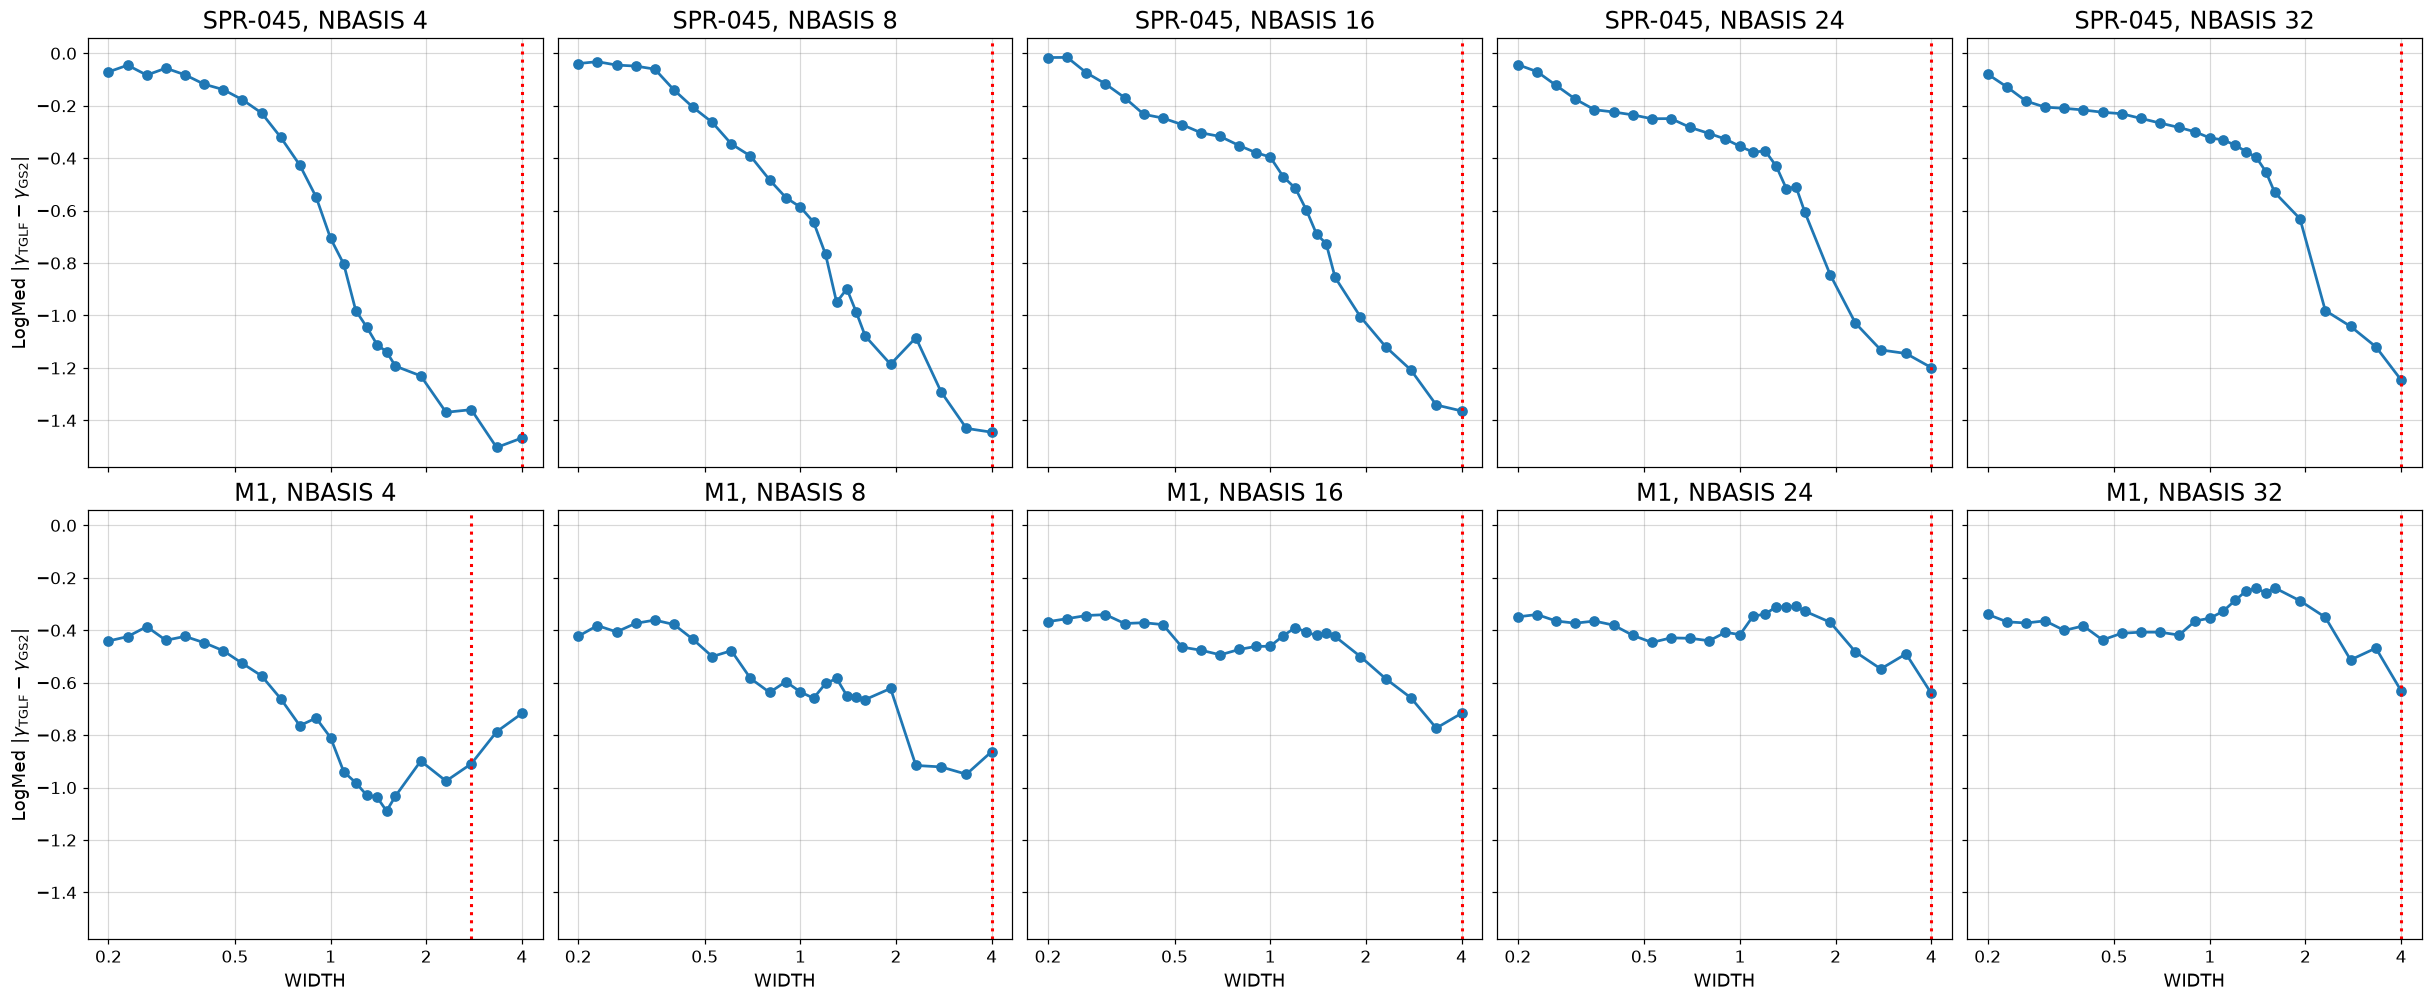

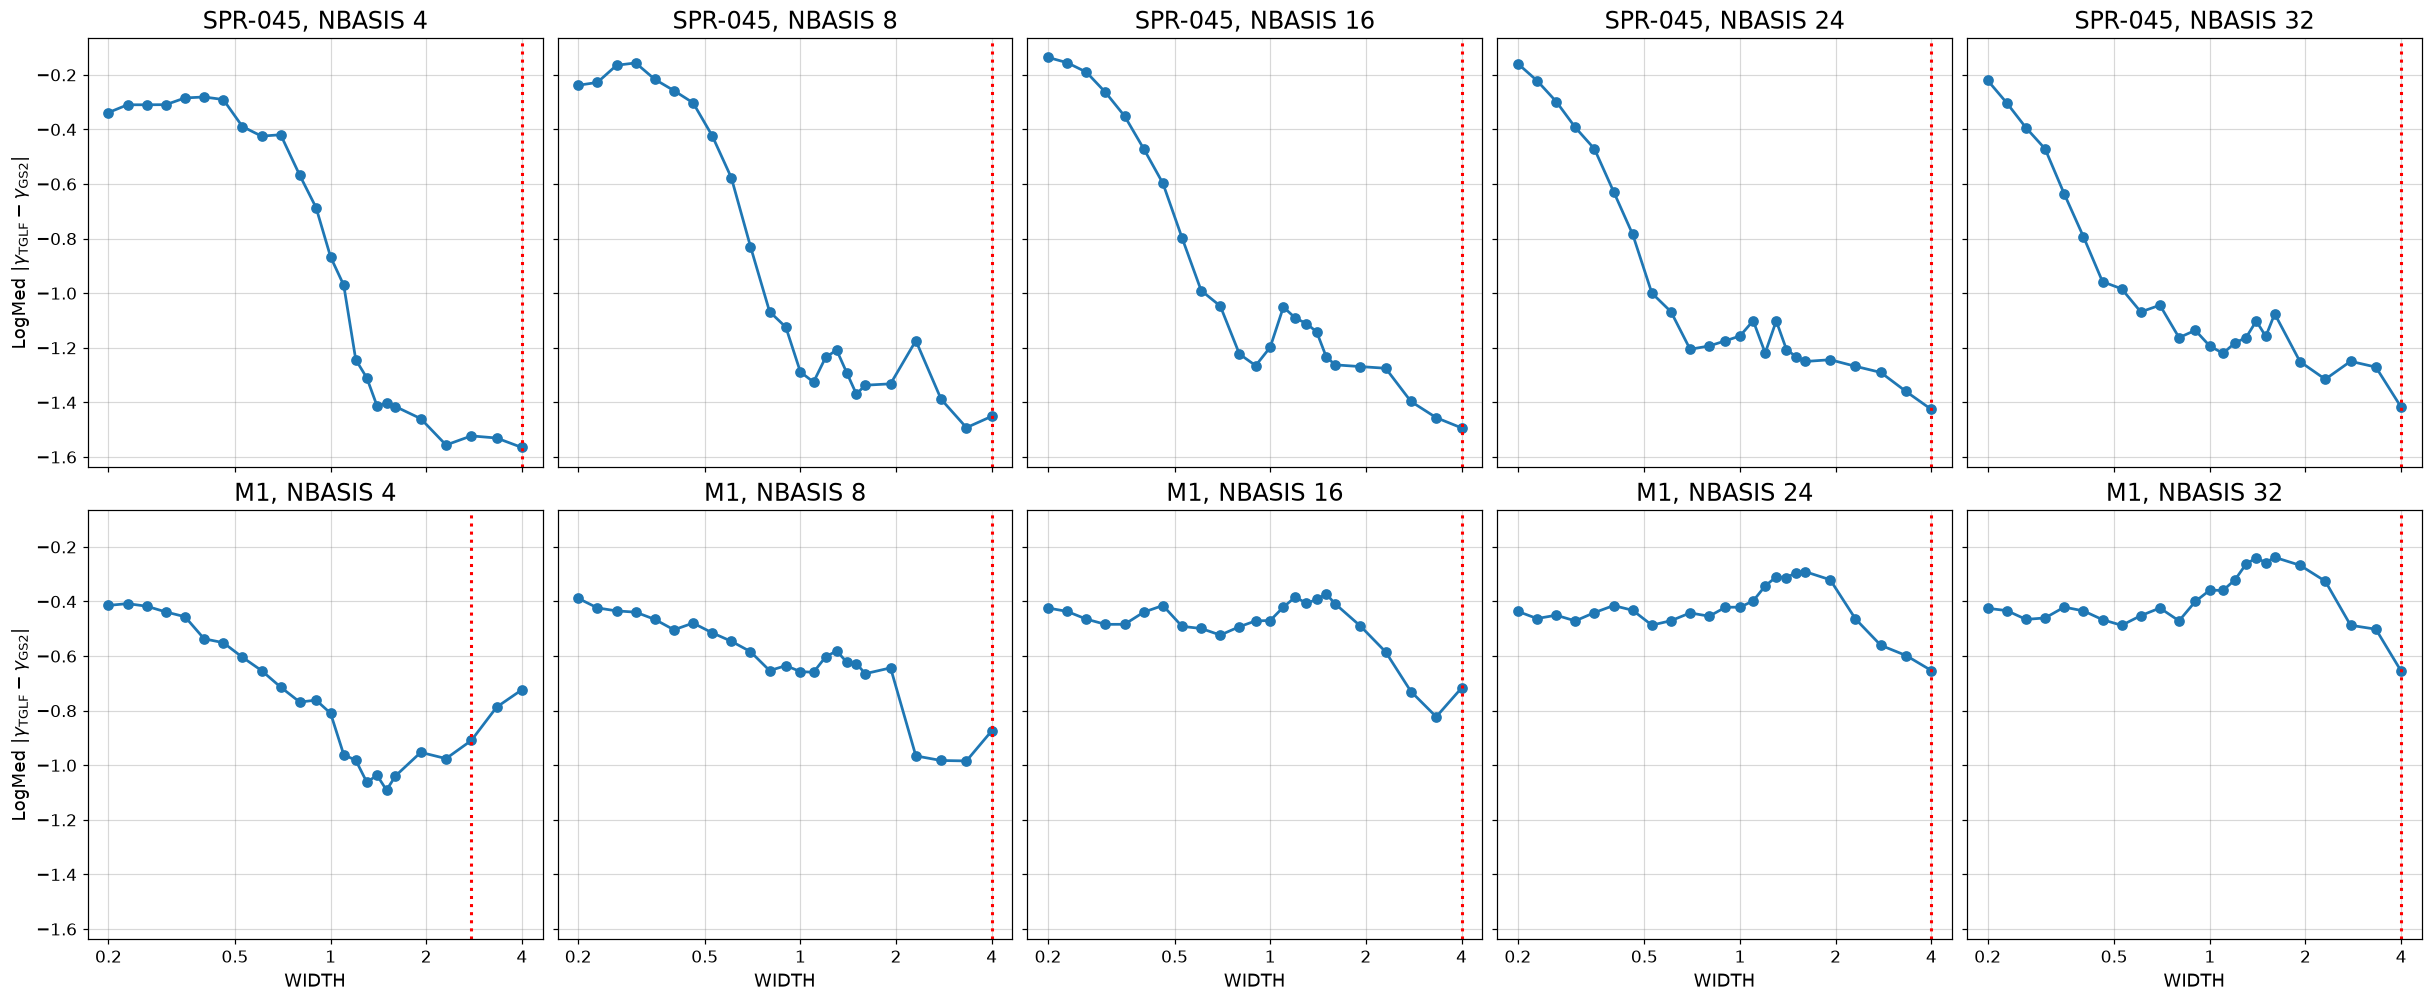

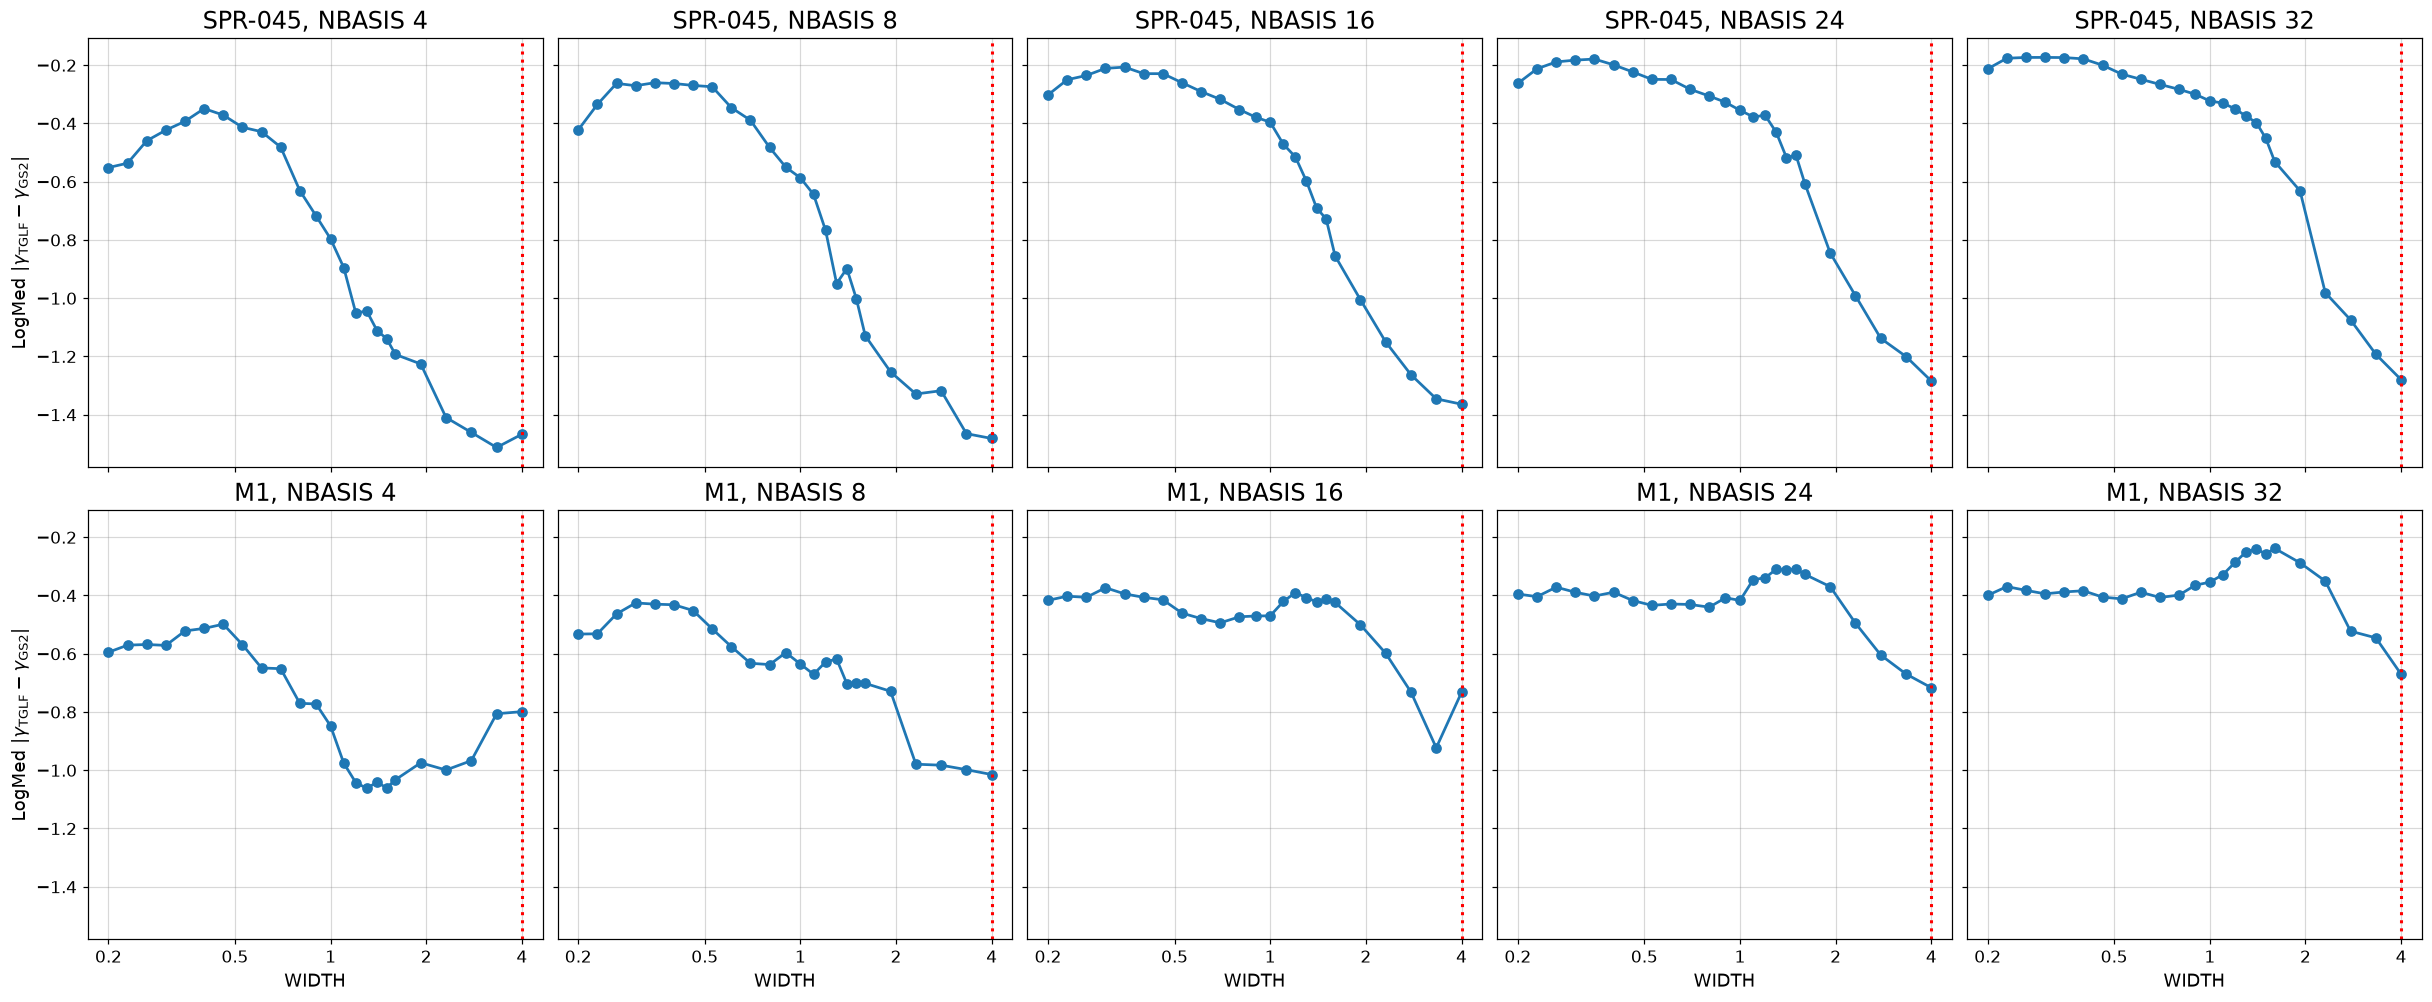

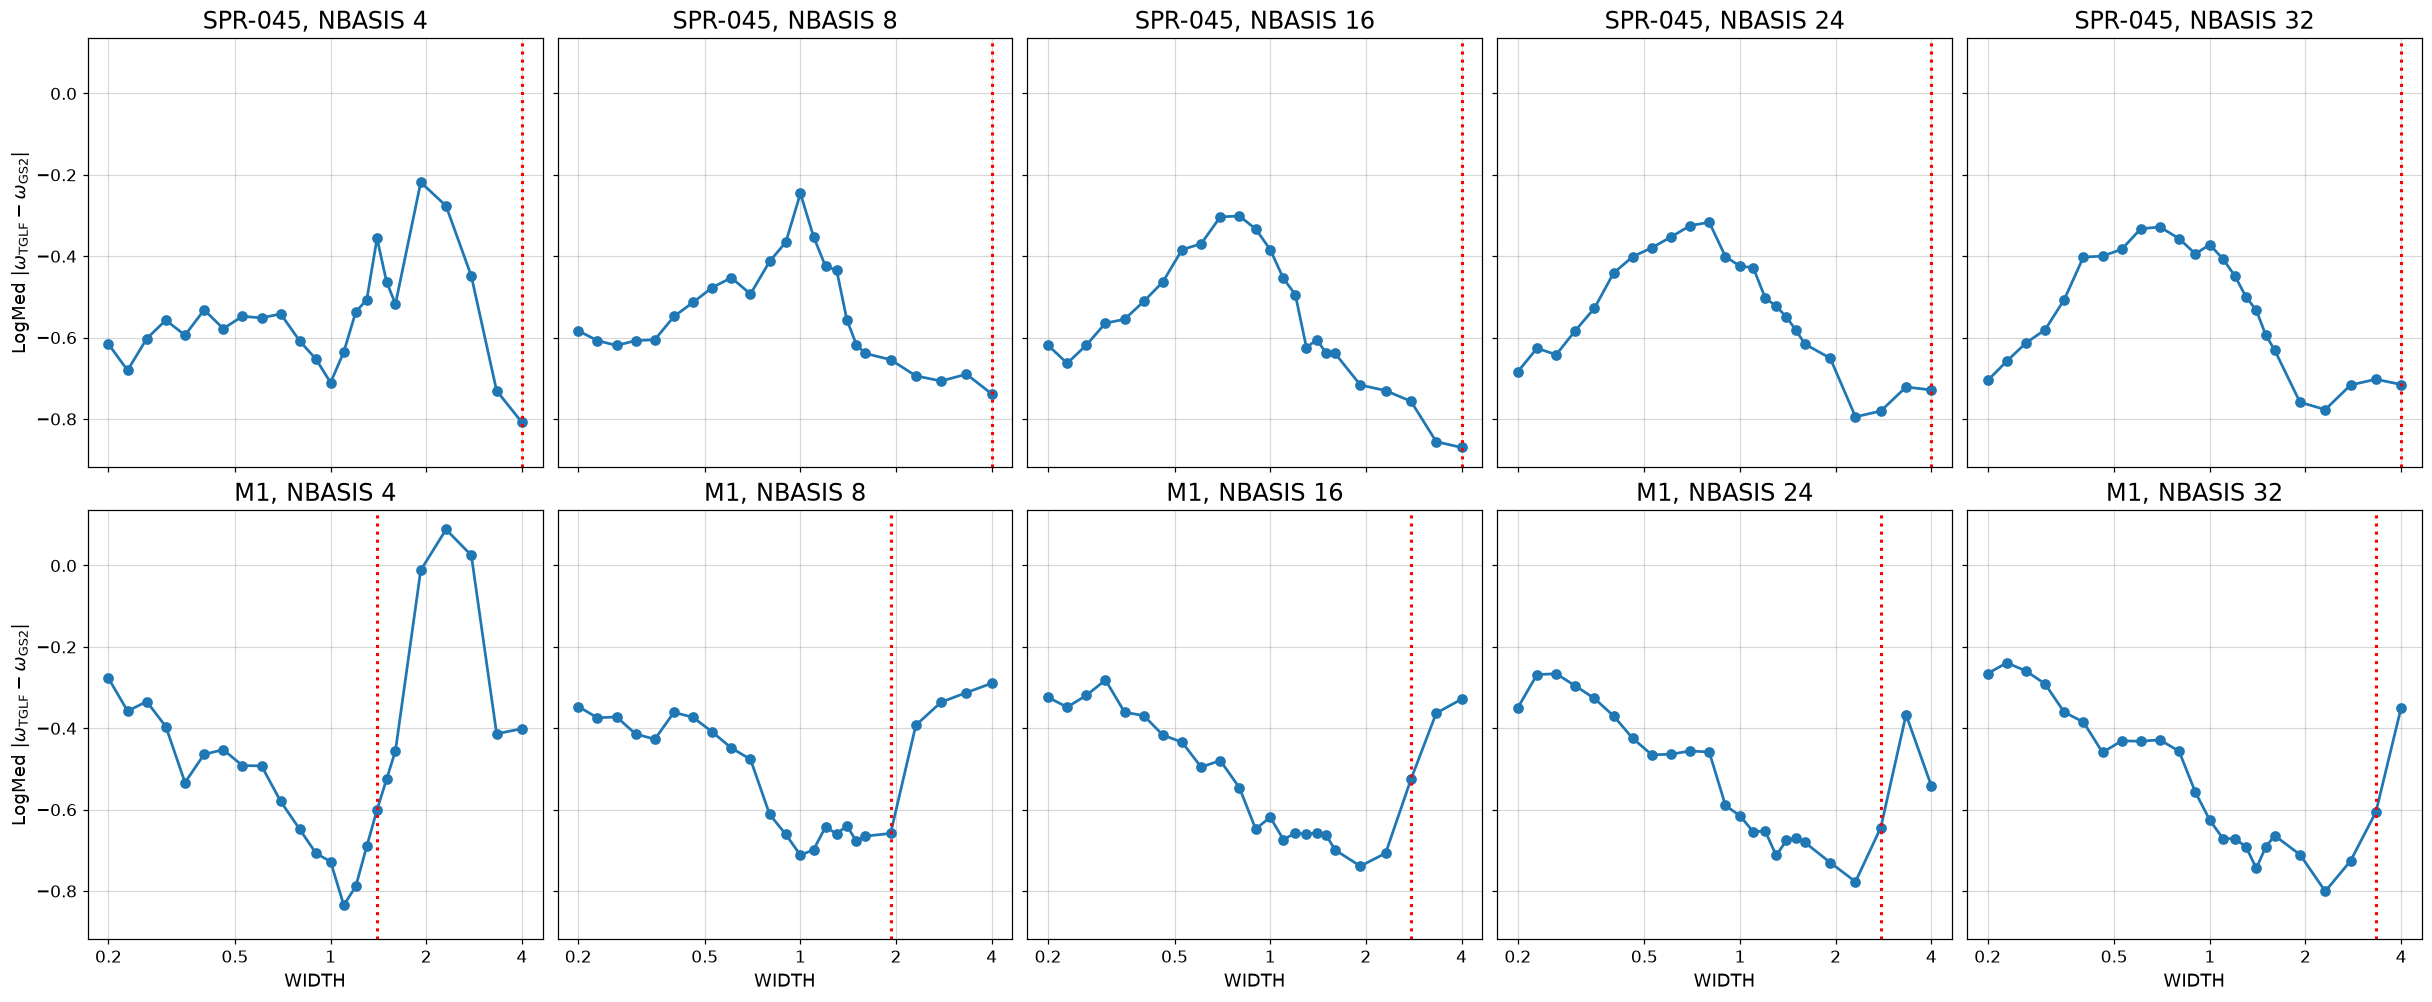

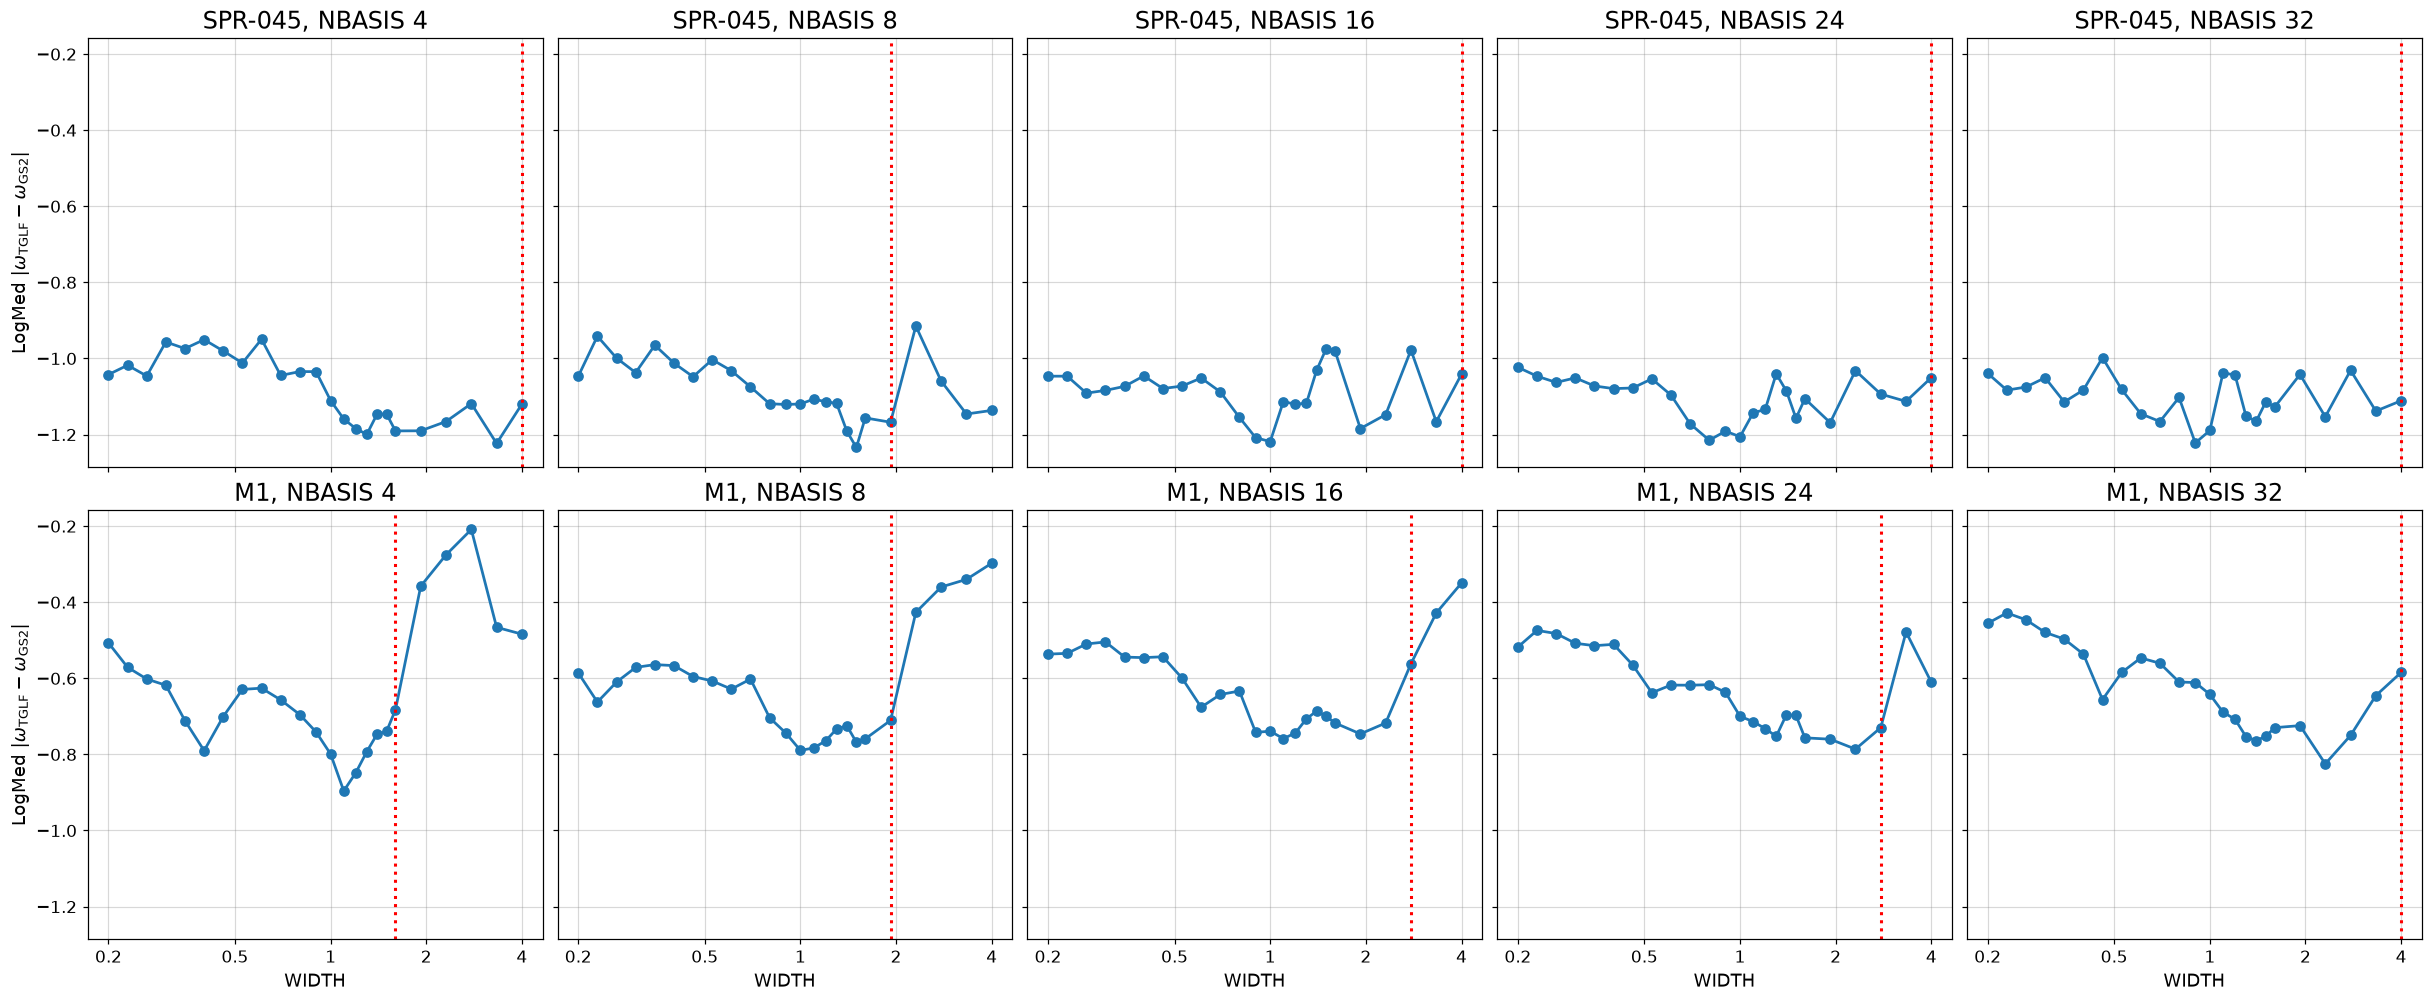

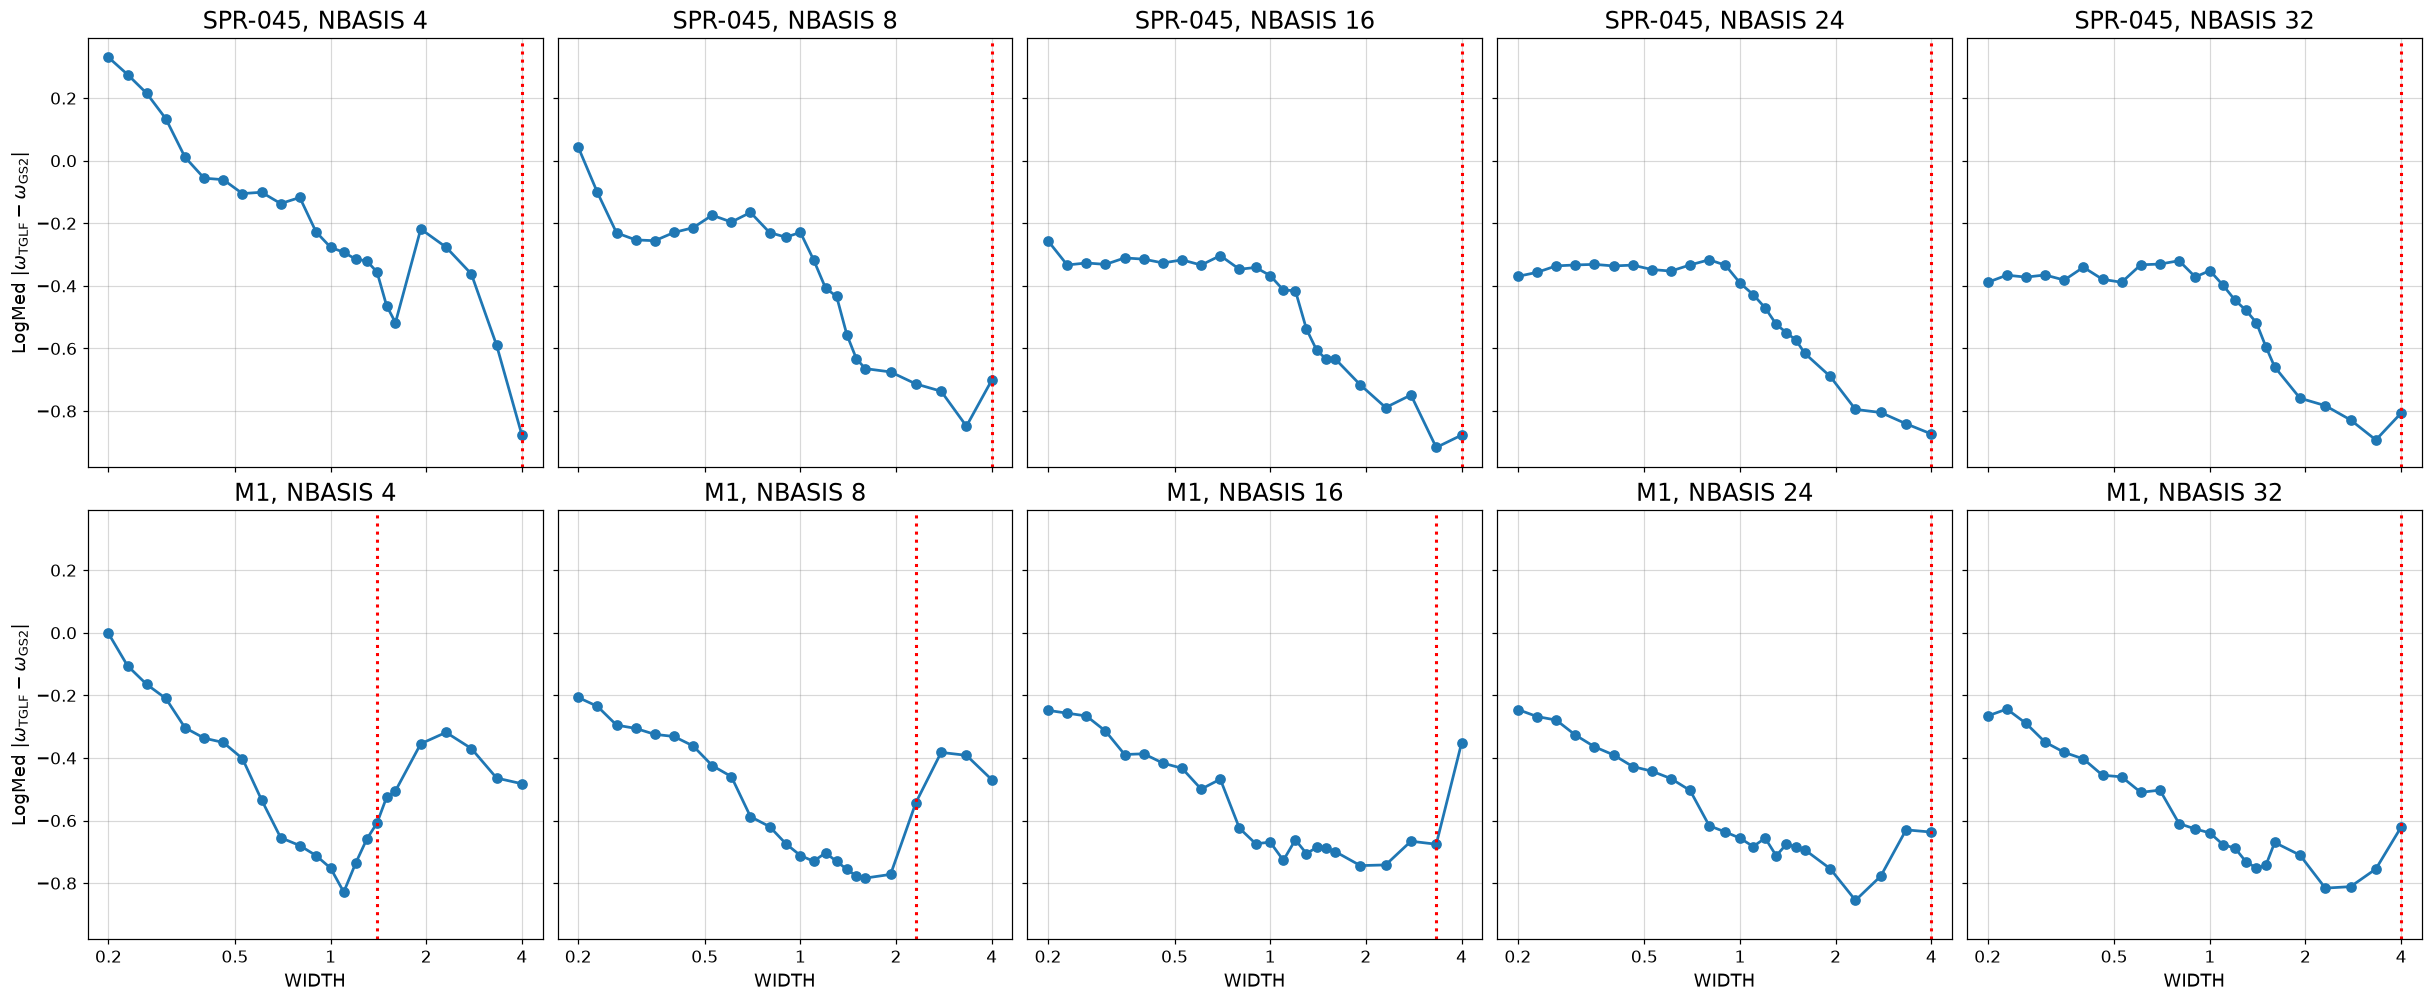

cases with no unstable TGLF mode (omega dropped), summed over widths: {('M1', 'fm0p1'): 288, ('M1', 'fp0p0'): 104, ('M1', 'fp2p0'): 194, ('SPR-045', 'fm0p1'): 20, ('SPR-045', 'fp0p0'): 15, ('SPR-045', 'fp2p0'): 221}


In [7]:
acc = []
for (db, ft, nb, W), gamma in gamma_fixed.items():
    k = gs2[db]["kbm"]
    acc.append(dict(db=db, ft=ft, nb=nb, W=W, gamma_logmed=np.log10(np.median(np.abs(gamma[k] - gs2[db]["gamma"][k]))),
                    omega_logmed=np.log10(np.nanmedian(np.abs(omega_fixed[db, ft, nb, W][k] - gs2[db]["omega"][k]))),
                    n_nomode=int((gamma[k] == 0).sum())))
acc = pd.DataFrame(acc).sort_values(["db", "ft", "nb", "W"])
acc["ok_gamma"] = acc.gamma_logmed <= acc.groupby(["db", "ft", "nb"]).gamma_logmed.transform("min") + np.log10(2)
acc["ok_omega"] = acc.omega_logmed <= acc.groupby(["db", "ft", "nb"]).omega_logmed.transform("min") + np.log10(2)


def last_ok(a, metric, ok):
    i = int(a[metric].idxmin())
    while i + 1 < len(a) and a[ok][i + 1]:
        i += 1
    return a.W[i] if a[ok][i] else np.nan


def first_ok(a, metric, ok):
    i = int(a[metric].idxmin())
    while i > 0 and a[ok][i - 1]:
        i -= 1
    return a.W[i]


w_max_gam, w_max_om, window = {}, {}, []
for db in cases:
    for ft in filters:
        for nb in sections:
            a = acc[(acc.db == db) & (acc.ft == ft) & (acc.nb == nb)].reset_index(drop=True)
            w_max_gam[db, ft, nb], w_max_om[db, ft, nb] = last_ok(a, "gamma_logmed", "ok_gamma"), last_ok(a, "omega_logmed", "ok_omega")
            best = a.loc[a.gamma_logmed.idxmin()]
            window.append(dict(db=db, ft=ft, nb=nb, W_best=best.W, gamma_logmed_best=best.gamma_logmed,
                               W_lo=first_ok(a, "gamma_logmed", "ok_gamma"), W_hi=w_max_gam[db, ft, nb],
                               W_best_omega=a.W[a.omega_logmed.idxmin()], omega_logmed_best=a.omega_logmed.min(),
                               W_lo_omega=first_ok(a, "omega_logmed", "ok_omega"), W_hi_omega=w_max_om[db, ft, nb]))
window = pd.DataFrame(window)
print(window.round(3).to_string(index=False))


def per_nbasis(cols, labels, ylabel, w_max, ft):
    fig, axes = plt.subplots(len(cases), len(sections), figsize=(22, 9), sharex=True, sharey=True, squeeze=False)
    for r, db in enumerate(cases):
        for j, nb in enumerate(sections):
            ax = axes[r, j]
            a = acc[(acc.db == db) & (acc.ft == ft) & (acc.nb == nb)]
            for col, lab, cc in zip(cols, labels, ("C0", "C3")):
                ax.plot(a.W, a[col], color=cc, label=lab)
            if np.isfinite(w_max[db, ft, nb]):
                ax.axvline(w_max[db, ft, nb], color="red", ls=":", lw=2, marker="")
            ax.set(xscale="log")
            ax.set_title(f"{db}, NBASIS {nb}", fontsize=fs_title)
            if r == len(cases) - 1:
                ax.set_xlabel("WIDTH")
                log_xticks(ax, [0.2, 0.5, 1, 2, 4])
        axes[r, 0].set_ylabel(ylabel)
    if len(cols) > 1:
        axes[0, 0].legend(fontsize=fs_legend)
    plt.show()
    return fig


fig5 = {ft: per_nbasis(["gamma_logmed"], [None], r"LogMed $|\gamma_{\rm TGLF}-\gamma_{\rm GS2}|$", w_max_gam, ft) for ft in filters}
fig5w = {ft: per_nbasis(["omega_logmed"], [None], r"LogMed $|\omega_{\rm TGLF}-\omega_{\rm GS2}|$", w_max_om, ft) for ft in filters}
print("cases with no unstable TGLF mode (omega dropped), summed over widths:", acc.groupby(["db", "ft"]).n_nomode.sum().to_dict())

## Fixed width vs FIND_WIDTH on the same cases

Best fixed (WIDTH, NBASIS_MAX) per database and FILTER against the real FIND_WIDTH runs (NBASIS_MAX 32) and the oracle,
GS2-KBM population, LogMed $|\gamma - \gamma_{\rm GS2}|$ and LogMed $|\omega - \omega_{\rm GS2}|$.

In [8]:
rows = []
for db in cases:
    k = gs2[db]["kbm"]
    for ft in filters:
        best = acc[(acc.db == db) & (acc.ft == ft)].sort_values("gamma_logmed").iloc[0]
        row = dict(db=db, ft=ft, fixed=f"W {best.W:g} / NB {best.nb}", fixed_gamma=best.gamma_logmed, fixed_omega=best.omega_logmed,
                   oracle_gamma=np.log10(np.median(np.abs(oracle[db, ft]["gamma"][k] - gs2[db]["gamma"][k]))))
        for search in search_ranges:
            for nb_search in (2, 32):
                key = (db, ft, search, nb_search)
                row[f"fw_{search}_nbmin{nb_search}_gamma"] = np.log10(np.median(np.abs(gamma_fw[key][k] - gs2[db]["gamma"][k])))
                row[f"fw_{search}_nbmin{nb_search}_omega"] = np.log10(np.nanmedian(np.abs(omega_fw[key][k] - gs2[db]["omega"][k])))
        rows.append(row)
versus = pd.DataFrame(rows)
print(versus.round(3).T.to_string())

                                         0           1                2             3             4             5
db                                 SPR-045     SPR-045          SPR-045            M1            M1            M1
ft                                   fp0p0       fp2p0            fm0p1         fp0p0         fp2p0         fm0p1
fixed                      W 3.3302 / NB 4  W 4 / NB 4  W 3.3302 / NB 4  W 1.5 / NB 4  W 1.5 / NB 4  W 1.3 / NB 4
fixed_gamma                         -1.503      -1.565           -1.513        -1.089        -1.091        -1.062
fixed_omega                         -0.731       -1.12            -0.59        -0.526        -0.739        -0.659
oracle_gamma                        -1.683      -2.286             -1.7         -1.53        -1.639        -1.569
fw_0.3-1.65_nbmin2_gamma            -0.205      -0.788            -0.17        -0.349        -0.408        -0.396
fw_0.3-1.65_nbmin2_omega             -0.47      -1.094           -0.401        -0.702   

## Figures for H1 and H2

fig1 (H1): median $|\log_{10} W^*(\mathrm{NB}_s)/W^*(32)|$ vs NB$_s$, search range 0.2-4.0; solid = emulated on the grid,
markers = real FIND_WIDTH runs; dashed red = the growth rate's own NBASIS convergence at that width (see the table above).
One panel per (database, FILTER), GS2-KBM population.

fig2: LogMed $|\gamma_{\rm FW} - \gamma_{\rm GS2}|$ of the FIND_WIDTH result vs NB$_s$ (NBASIS_MAX 32), both search ranges;
horizontal references: the best fixed WIDTH at NBASIS_MAX 32 (black dashed) and the oracle $W_{\rm truth}$ (grey dotted, a bound).

fig3 (H2): median $\log_{10} W^*(\mathrm{NB}_s)/W_{\rm truth}$ vs NB$_s$, one line per FILTER, search range 0.2-4.0
(solid emulated, markers real); > 0 means the max-$\gamma$ width is wider than the width closest to GS2.

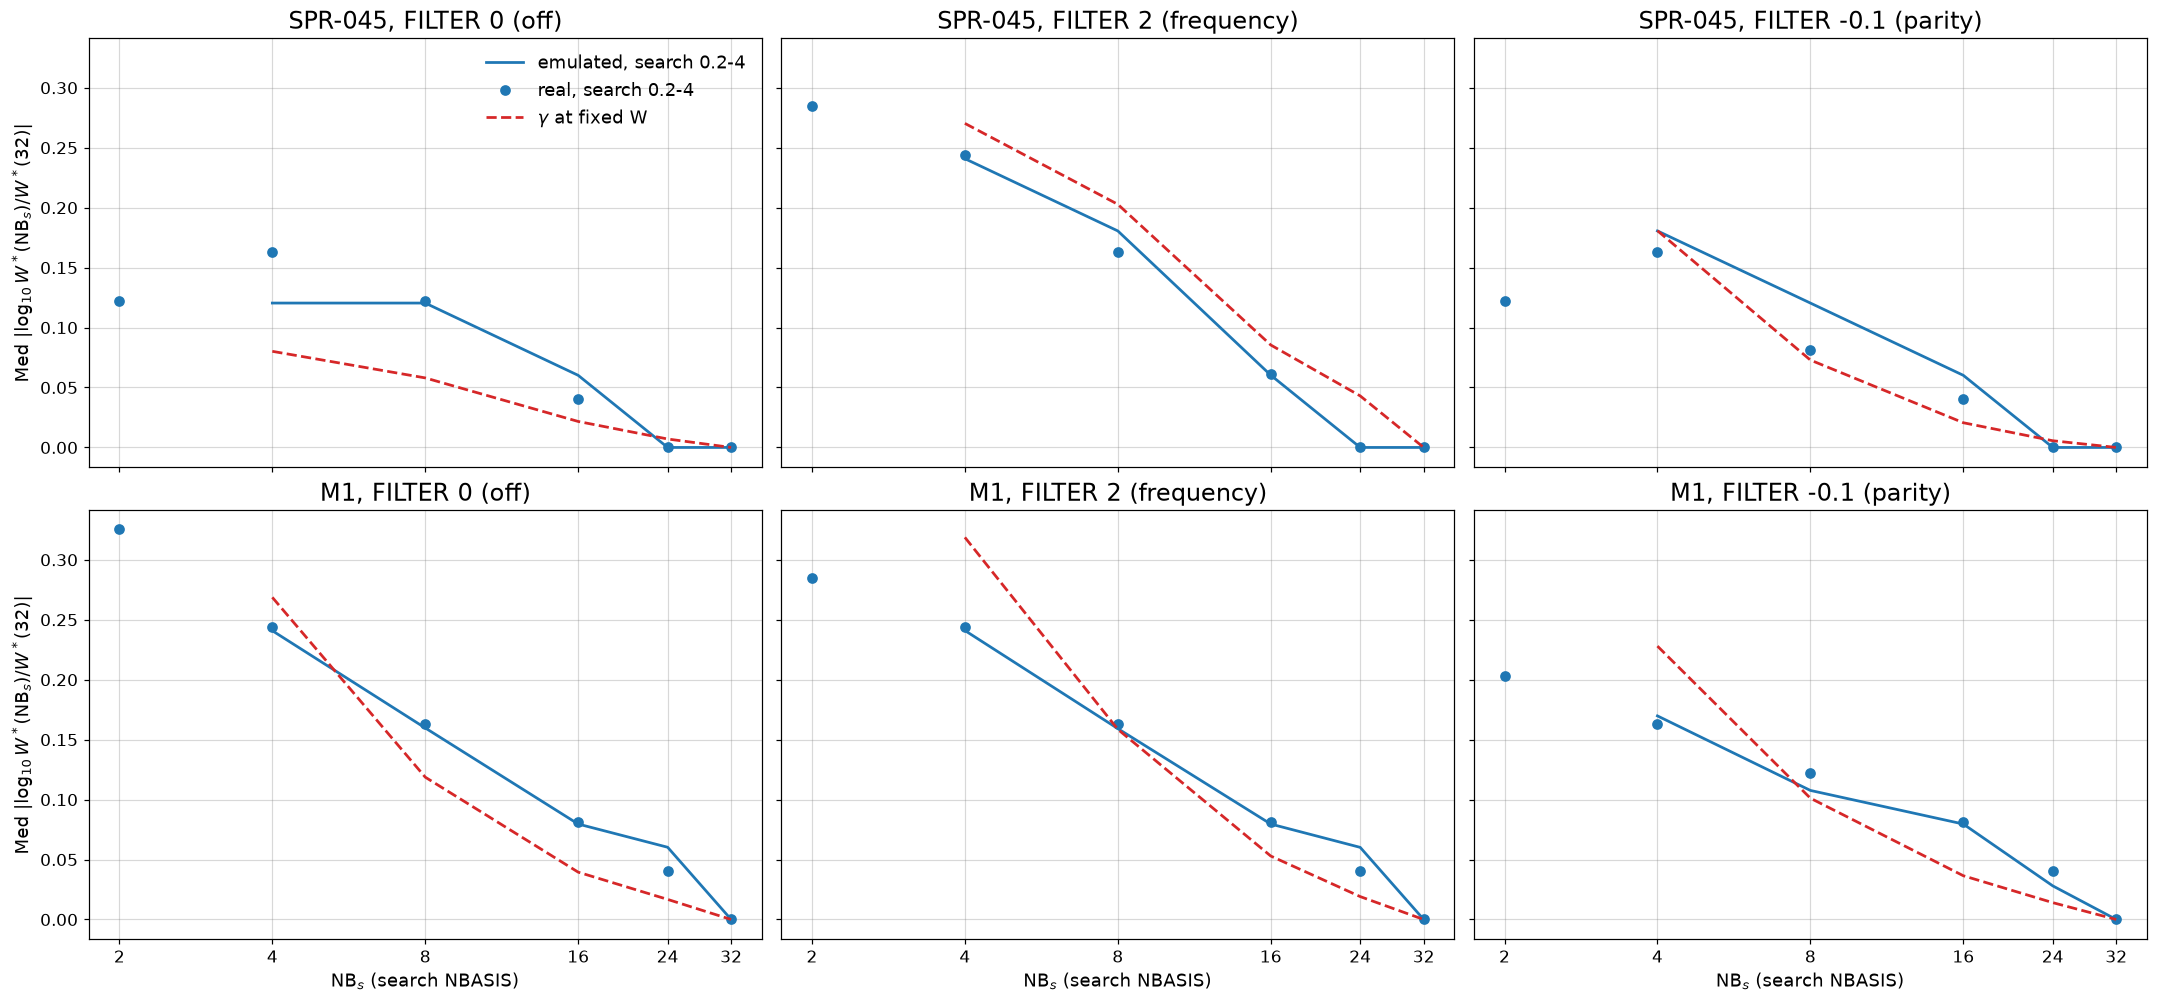

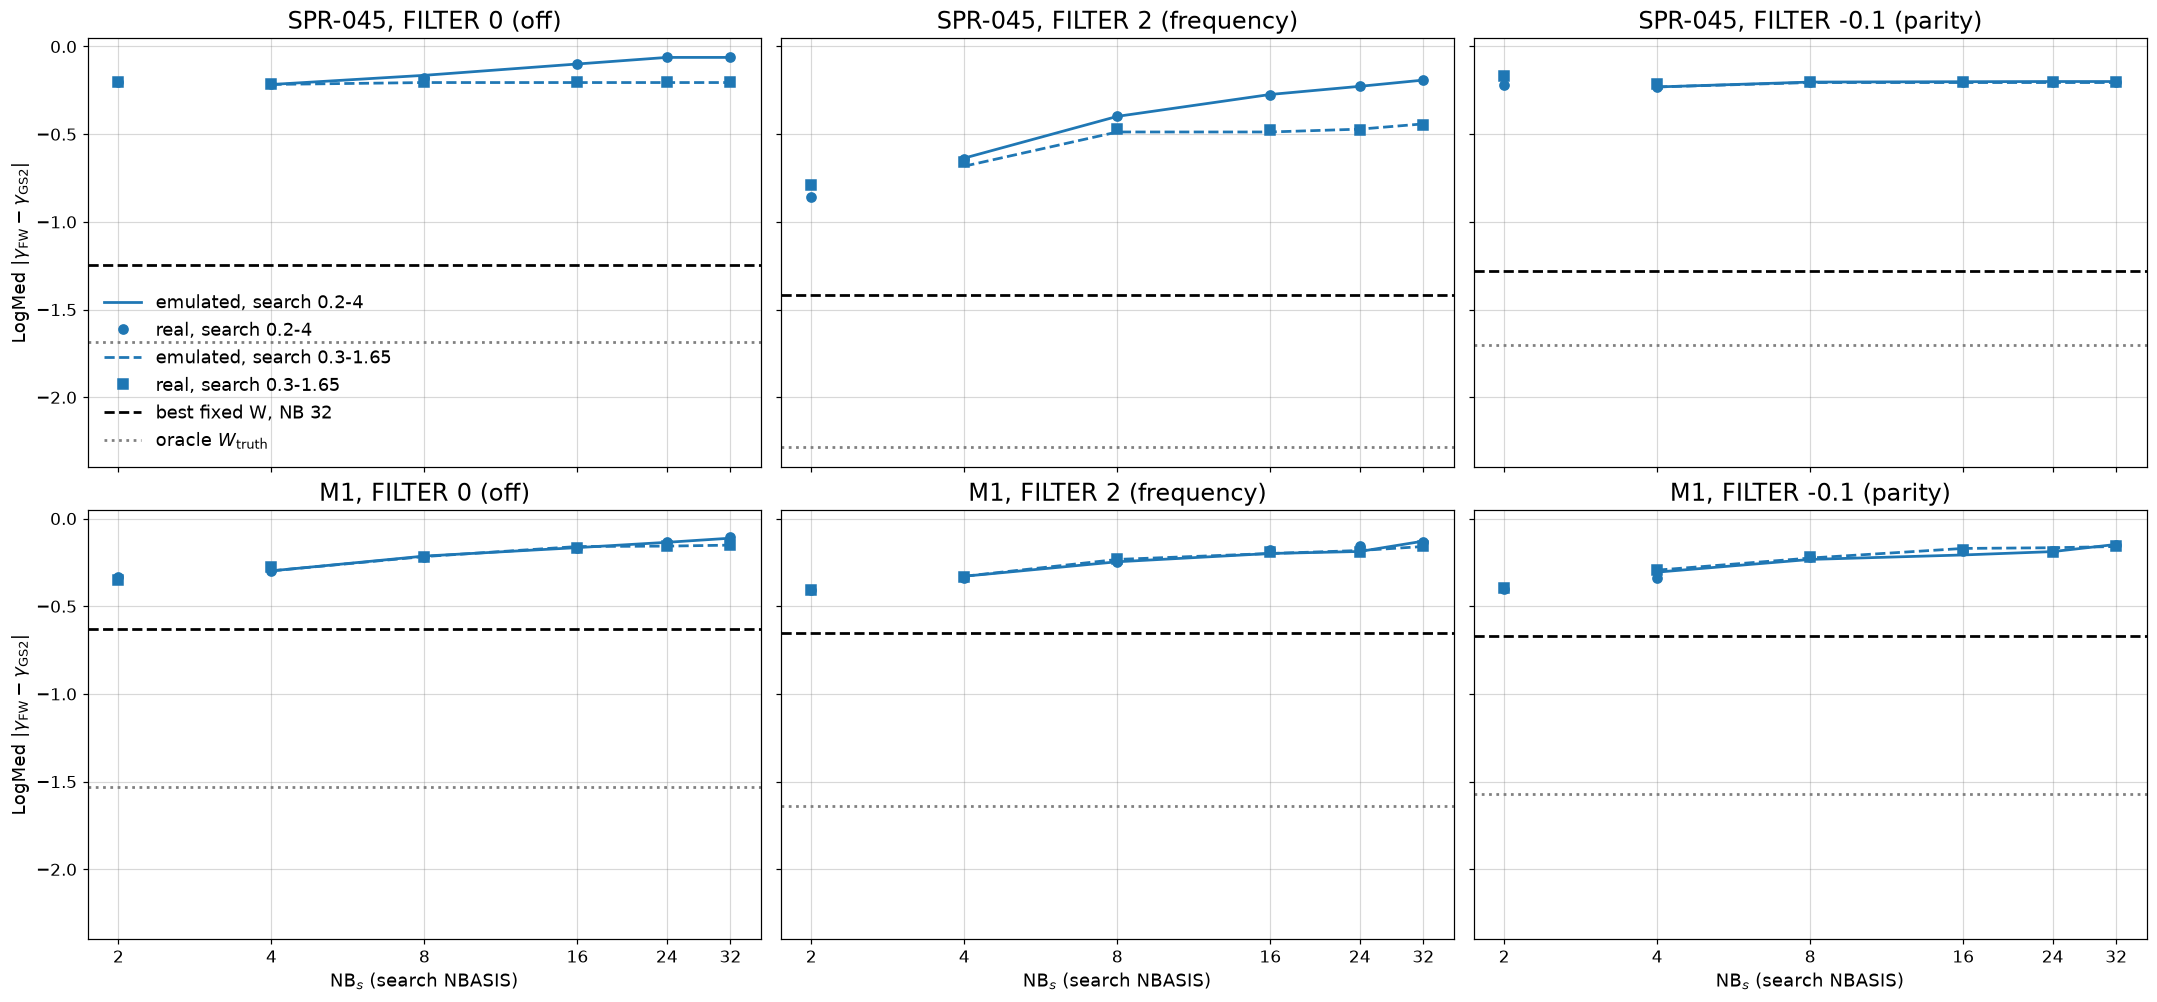

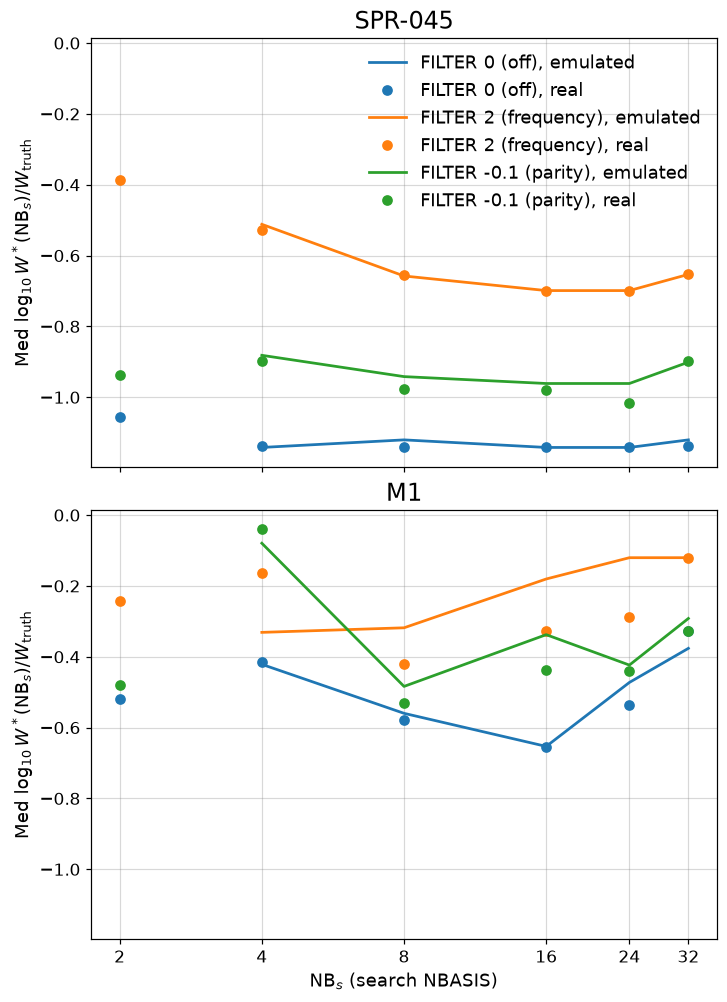

In [9]:
def h_panel(kind_style, column, ylabel, refs=None, filters_in_panel=False):
    columns = [None] if filters_in_panel else list(filters)
    fig, axes = plt.subplots(len(cases), len(columns), figsize=(6.5 * len(columns), 9), sharex=True, sharey=True, squeeze=False)
    for r, db in enumerate(cases):
        for j, col_ft in enumerate(columns):
            ax = axes[r, j]
            for c, ft in enumerate(filters if filters_in_panel else [col_ft]):
                colour = f"C{c}" if filters_in_panel else "C0"
                for (kind, search), style in kind_style.items():
                    d = hyp[(hyp.db == db) & (hyp.ft == ft) & (hyp.kind == kind) & (hyp.search == search)]
                    label = f"{filter_labels[ft]}, {kind}" if filters_in_panel else f"{kind}, search {search}"
                    ax.plot(d.nb_s, d[column], color=colour, label=label if r == 0 else None, **style)
                if refs:
                    refs(ax, db, ft)
            ax.set(xscale="log", xlabel="NB$_s$ (search NBASIS)" if r == len(cases) - 1 else None)
            ax.set_title(db if filters_in_panel else f"{db}, {filter_labels[col_ft]}", fontsize=fs_title)
            log_xticks(ax, search_nbasis)
        axes[r, 0].set_ylabel(ylabel)
    axes[0, 0].legend(fontsize=fs_legend)
    plt.show()
    return fig


solid, dots = dict(ls="-", marker=""), dict(ls="", marker="o")


def gamma_convergence(ax, db, ft):
    d = hyp[(hyp.db == db) & (hyp.ft == ft) & (hyp.kind == "emulated") & (hyp.search == "0.2-4")]
    ax.plot(d.nb_s, d.shift_gamma, color="C3", ls="--", marker="", label=r"$\gamma$ at fixed W" if db == "SPR-045" else None)


def fixed_and_oracle(ax, db, ft):
    k = gs2[db]["kbm"]
    ax.axhline(acc[(acc.db == db) & (acc.ft == ft) & (acc.nb == 32)].gamma_logmed.min(), color="k", ls="--", marker="",
               label="best fixed W, NB 32" if db == "SPR-045" else None)
    ax.axhline(np.log10(np.median(np.abs(oracle[db, ft]["gamma"][k] - gs2[db]["gamma"][k]))), color="0.5", ls=":", marker="",
               label=r"oracle $W_{\rm truth}$" if db == "SPR-045" else None)


fig1 = h_panel({("emulated", "0.2-4"): solid, ("real", "0.2-4"): dots}, "shift_W",
               r"Med $|\log_{10} W^*(\mathrm{NB}_s)/W^*(32)|$", refs=gamma_convergence)
fig2 = h_panel({("emulated", "0.2-4"): solid, ("real", "0.2-4"): dots, ("emulated", "0.3-1.65"): dict(ls="--", marker=""),
                ("real", "0.3-1.65"): dict(ls="", marker="s")}, "logmed_gamma", r"LogMed $|\gamma_{\rm FW}-\gamma_{\rm GS2}|$",
               refs=fixed_and_oracle)
fig3 = h_panel({("emulated", "0.2-4"): solid, ("real", "0.2-4"): dots}, "to_truth",
               r"Med $\log_{10} W^*(\mathrm{NB}_s)/W_{\rm truth}$", filters_in_panel=True)

In [10]:
out = ROOT / "Plots" / analysis_name
out.mkdir(parents=True, exist_ok=True)
for name, fig in (("fig1_search_width_vs_nbasis_min", fig1), ("fig2_find_width_gamma_err_vs_nbasis_min", fig2),
                  ("fig3_search_width_vs_truth", fig3)):
    fig.savefig(out / f"{name}.png", bbox_inches="tight")
for ft in filters:
    fig5[ft].savefig(out / f"fig5_tglf_gamma_err_vs_width_per_nbasis_{ft.replace('fp', 'f')}.png", bbox_inches="tight")
    fig5w[ft].savefig(out / f"fig5b_tglf_omega_err_vs_width_per_nbasis_{ft.replace('fp', 'f')}.png", bbox_inches="tight")
# medians only, no per-case rows
for name, table in (("hypotheses", hyp), ("validation", validation), ("accuracy_vs_width", acc), ("width_window", window), ("fixed_vs_find_width", versus)):
    table.round(4).to_csv(out / f"{name}.csv", index=False)
print(sorted(p.name for p in out.iterdir()))

['accuracy_vs_width.csv', 'fig1_search_width_vs_nbasis_min.png', 'fig2_find_width_gamma_err_vs_nbasis_min.png', 'fig3_search_width_vs_truth.png', 'fig5_tglf_gamma_err_vs_width_per_nbasis_f0p0.png', 'fig5_tglf_gamma_err_vs_width_per_nbasis_f2p0.png', 'fig5_tglf_gamma_err_vs_width_per_nbasis_fm0p1.png', 'fig5b_tglf_omega_err_vs_width_per_nbasis_f0p0.png', 'fig5b_tglf_omega_err_vs_width_per_nbasis_f2p0.png', 'fig5b_tglf_omega_err_vs_width_per_nbasis_fm0p1.png', 'fixed_vs_find_width.csv', 'hypotheses.csv', 'validation.csv', 'width_window.csv']
